# Sumativa 2: Simulación y Remuestreo
**Magíster en Ciencia de Datos e Inteligencia Artificial - UNAB**

**Integrantes:** Verónica Durán, Raúl Moya, Daniela Rojas, Manuel Sánchez  
**Grupo:** 2  
**Curso:** MCDI501 - Estadística Computacional para la Toma de Decisiones  
**Evaluación:** Sumativa 2  
**Dataset:** Online Shoppers Purchasing Intention  
**Fase 3:** Simulación, remuestreo y evaluación de robustez

## Objetivo
Validar y profundizar los resultados de la Sumativa 1 mediante bootstrap, pruebas de permutación, evaluación de estabilidad de correlaciones, simulación Monte Carlo, datos sintéticos, análisis de sensibilidad y evaluación de robustez.

> **Pregunta del proyecto:** ¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?

Las conclusiones se interpretan como asociaciones estadísticas y no como relaciones causales.


## 1. Trazabilidad S1 → S2

La evaluación se construye explícitamente sobre los resultados obtenidos en S1:

| Resultado S1 | Referencia | Validación S2 |
|---|---:|---|
| Media `ProductRelated_Duration` | 1194,7462 | Bootstrap percentil + BCa |
| Media `PageValues` | 5,8893 | Bootstrap percentil + BCa |
| Media `ExitRates` | 0,0431 | Bootstrap percentil + BCa |
| `PageValues` según `Revenue` | Mann–Whitney U = 17.166.757 | Permutación de diferencia de medias |
| `VisitorType × Revenue` | χ² = 135,2519 | Permutación manteniendo χ² |
| `BounceRates–ExitRates` | r = 0,913004 | Bootstrap |
| `ProductRelated–ProductRelated_Duration` | r = 0,860927 | Bootstrap |
| `Informational–Informational_Duration` | r = 0,618955 | Bootstrap |
| `Administrative–Administrative_Duration` | r = 0,601583 | Bootstrap |
| `Revenue=True` | ≈15,47 % | Monte Carlo + sensibilidad |

S2 no reemplaza los resultados de S1: evalúa su estabilidad mediante procedimientos computacionales.


In [1]:
# 2. Entorno y reproducibilidad
from pathlib import Path
from IPython.display import display
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_RESAMPLES = 10_000
ALPHA = 0.05

rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

print("Entorno preparado.")
print("Semilla:", RANDOM_STATE)
print("Remuestras/iteraciones:", f"{N_RESAMPLES:,}")


Entorno preparado.
Semilla: 42
Remuestras/iteraciones: 10,000


### Reproducibilidad

Los métodos de simulación y remuestreo incorporan aleatoriedad. Se utiliza `np.random.default_rng(42)` para obtener resultados reproducibles. La semilla fija la secuencia pseudoaleatoria de esta ejecución, pero no elimina la naturaleza aleatoria del procedimiento.


In [2]:
# 3. Carga y control de continuidad con S1
rutas = [
    Path("data/raw/online_shoppers_intention.csv"),
    Path("../data/raw/online_shoppers_intention.csv")
]

ruta = next((p for p in rutas if p.exists()), None)

if ruta is None:
    raise FileNotFoundError("No se encontró el CSV en data/raw.")

df = pd.read_csv(ruta)

if df["Revenue"].dtype == object:
    df["Revenue"] = (
        df["Revenue"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False})
    )

if df["Revenue"].isna().any():
    raise ValueError("Revenue contiene valores no reconocidos.")

df["Revenue"] = df["Revenue"].astype(bool)

verificacion = pd.Series({
    "Sesiones": len(df),
    "Variables": df.shape[1],
    "Faltantes": int(df.isna().sum().sum()),
    "Filas con valores idénticos": int(df.duplicated().sum()),
    "Compras": int(df["Revenue"].sum()),
    "No compras": int((~df["Revenue"]).sum()),
    "Tasa de conversión": df["Revenue"].mean()
})

display(verificacion.to_frame("S2"))

assert df.shape == (12330, 18)
assert df.isna().sum().sum() == 0


,S2
Sesiones,"12,330.000000"
Variables,18.000000
Faltantes,0.000000
Filas con valores idénticos,125.000000
Compras,"1,908.000000"
No compras,"10,422.000000"
Tasa de conversión,0.154745


Las filas con valores idénticos se documentan, pero no se eliminan automáticamente: igualdad en los atributos observados no demuestra que correspondan a una misma sesión. Esta decisión conserva el criterio metodológico de S1.


In [3]:
# 4. Parámetros de referencia S1
variables_ic = ["ProductRelated_Duration", "PageValues", "ExitRates"]

ref_s1 = pd.DataFrame({
    "variable": variables_ic,
    "media_S1": [1194.7462, 5.8893, 0.0431],
    "clasico_inf": [1160.9649, 5.5615, 0.0422],
    "clasico_sup": [1228.5275, 6.2170, 0.0439]
})

ref_s1["media_recalculada"] = [df[v].mean() for v in variables_ic]
display(ref_s1)


,variable,media_S1,clasico_inf,clasico_sup,media_recalculada
0,ProductRelated_Duration,"1,194.746200","1,160.964900","1,228.527500","1,194.746220"
1,PageValues,5.889300,5.561500,6.217000,5.889258
2,ExitRates,0.043100,0.042200,0.043900,0.043073


## 5. Bootstrap no paramétrico: validación de intervalos de confianza

Para cada uno de los tres parámetros seleccionados en S1 se realizan **10.000 remuestras con reemplazo**. Se estima la media y se calculan intervalos de confianza del 95 % mediante los métodos **percentil** y **BCa**.

Los intervalos bootstrap se comparan con los intervalos clásicos de S1. La cercanía entre métodos aporta evidencia de estabilidad inferencial; no implica que las distribuciones originales sean simétricas ni que la media sea siempre la medida descriptiva más representativa.


In [4]:
# 5.1 Función bootstrap para la media
def bootstrap_media(x, n_resamples=N_RESAMPLES, seed=RANDOM_STATE):
    x = np.asarray(x, dtype=float)

    # Distribución bootstrap para visualización y percentiles
    gen = np.random.default_rng(seed)
    n = len(x)
    boot_means = np.empty(n_resamples)

    batch = 250
    pos = 0
    while pos < n_resamples:
        b = min(batch, n_resamples - pos)
        idx = gen.integers(0, n, size=(b, n))
        boot_means[pos:pos+b] = x[idx].mean(axis=1)
        pos += b

    ci_percentil = np.quantile(boot_means, [0.025, 0.975])

    # BCa con scipy
    res_bca = stats.bootstrap(
        (x,),
        np.mean,
        confidence_level=0.95,
        n_resamples=n_resamples,
        method="BCa",
        random_state=np.random.default_rng(seed),
        batch=250
    )

    ci_bca = (
        res_bca.confidence_interval.low,
        res_bca.confidence_interval.high
    )

    return boot_means, ci_percentil, ci_bca


resultados_boot = {}
filas_boot = []

for i, v in enumerate(variables_ic):
    boot_means, ci_perc, ci_bca = bootstrap_media(
        df[v].to_numpy(),
        seed=RANDOM_STATE + i
    )

    resultados_boot[v] = boot_means

    ref = ref_s1.loc[ref_s1["variable"] == v].iloc[0]

    filas_boot.append({
        "variable": v,
        "media": df[v].mean(),
        "IC_clasico_inf": ref["clasico_inf"],
        "IC_clasico_sup": ref["clasico_sup"],
        "IC_percentil_inf": ci_perc[0],
        "IC_percentil_sup": ci_perc[1],
        "IC_BCa_inf": ci_bca[0],
        "IC_BCa_sup": ci_bca[1]
    })

tabla_boot = pd.DataFrame(filas_boot)
display(tabla_boot)


,variable,media,IC_clasico_inf,IC_clasico_sup,IC_percentil_inf,IC_percentil_sup,IC_BCa_inf,IC_BCa_sup
0,ProductRelated_Duration,"1,194.746220","1,160.964900","1,228.527500","1,161.361347","1,229.231743","1,162.484876","1,230.951845"
1,PageValues,5.889258,5.561500,6.217000,5.573059,6.222113,5.580391,6.234119
2,ExitRates,0.043073,0.042200,0.043900,0.042219,0.043940,0.042238,0.043959


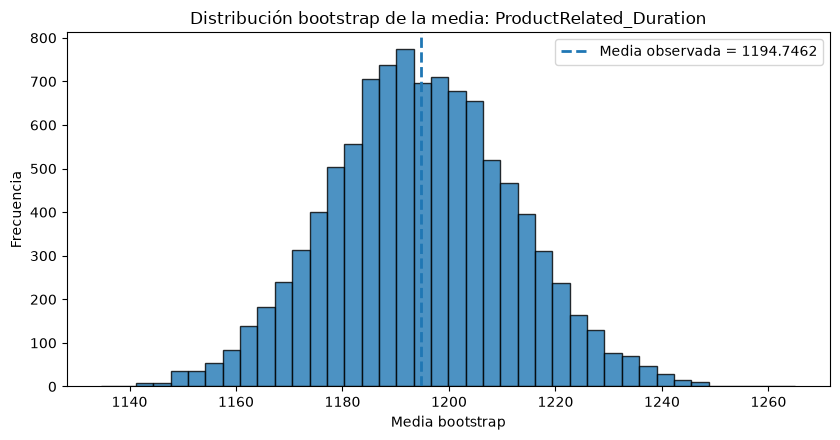

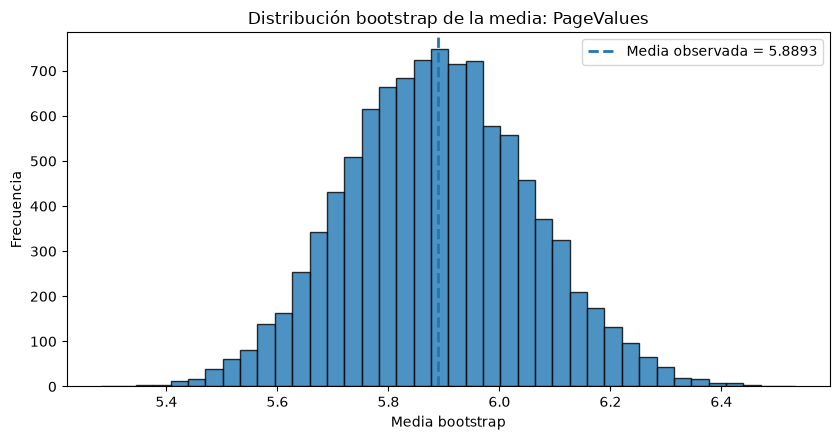

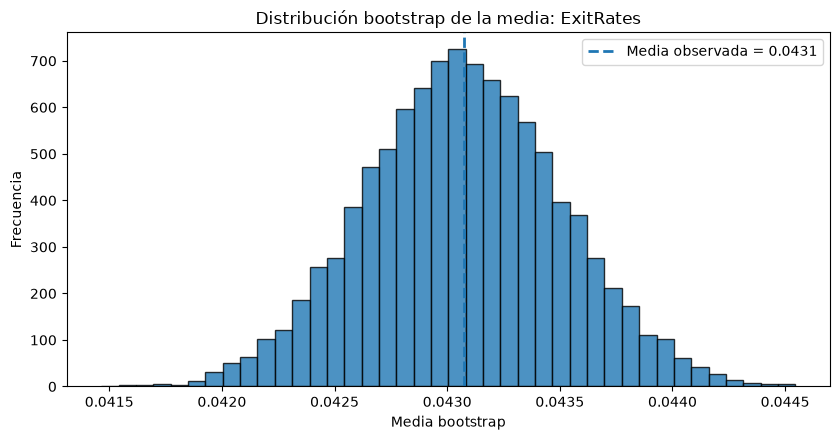

In [5]:
# 5.2 Distribuciones bootstrap
for v in variables_ic:
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    ax.hist(resultados_boot[v], bins=40, alpha=0.8, edgecolor="black")
    ax.axvline(df[v].mean(), linestyle="--", linewidth=2,
               label=f"Media observada = {df[v].mean():.4f}")
    ax.set_title(f"Distribución bootstrap de la media: {v}")
    ax.set_xlabel("Media bootstrap")
    ax.set_ylabel("Frecuencia")
    ax.legend()
    plt.tight_layout()
    plt.show()


### Interpretación del bootstrap

Los intervalos bootstrap percentil y BCa se comparan con los intervalos clásicos de S1. Si los límites permanecen próximos, la estimación de la media muestra estabilidad frente al remuestreo aun cuando las variables presenten asimetría.

La validación bootstrap debe interpretarse junto con el análisis de robustez posterior: un intervalo estable no implica que la media sea insensible a colas largas u observaciones extremas.


## 6. Validación de hipótesis mediante permutación

Se utilizan dos validaciones complementarias:

1. `PageValues × Revenue`: se compara la decisión de Mann–Whitney de S1 con una permutación basada en diferencia de medias.
2. `VisitorType × Revenue`: se mantiene el mismo estadístico χ² utilizado en S1 y se construye su distribución nula mediante 10.000 permutaciones.

La segunda validación permite una comparación especialmente directa entre el p-valor asintótico de S1 y un p-valor empírico de permutación.


### 6.1 `PageValues × Revenue`

En S1 `PageValues` se comparó según `Revenue` con Mann–Whitney. En S2 se aplica un test de permutación bilateral con **10.000 permutaciones**.

- **H₀:** bajo intercambiabilidad de las etiquetas de compra, no existe diferencia sistemática de `PageValues` entre grupos.
- **H₁:** existe diferencia entre los grupos.
- **α = 0,05.**

Se utiliza la **diferencia de medias** como estadístico de permutación por su interpretación directa en las unidades de `PageValues`. Se compara la decisión con Mann–Whitney, reconociendo que ambos procedimientos no prueban exactamente la misma hipótesis matemática.


Diferencia observada = 25.288520
p permutación = 9.999e-05
Referencia S1: Mann–Whitney U = 17,166,757; p < 1e-300


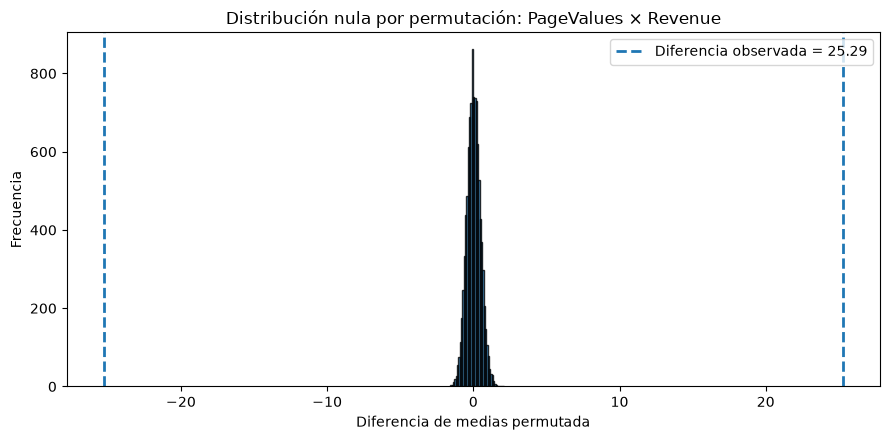

In [6]:
# 6.1 Permutación: PageValues según Revenue
x = df.loc[df["Revenue"], "PageValues"].to_numpy()
y = df.loc[~df["Revenue"], "PageValues"].to_numpy()

dif_obs = x.mean() - y.mean()

values = df["PageValues"].to_numpy()
n_true = len(x)

rng_perm = np.random.default_rng(RANDOM_STATE)
perm_diffs = np.empty(N_RESAMPLES)

for i in range(N_RESAMPLES):
    perm = rng_perm.permutation(values)
    perm_diffs[i] = perm[:n_true].mean() - perm[n_true:].mean()

p_perm = (
    np.sum(np.abs(perm_diffs) >= abs(dif_obs)) + 1
) / (N_RESAMPLES + 1)

print(f"Diferencia observada = {dif_obs:.6f}")
print(f"p permutación = {p_perm:.6g}")
print("Referencia S1: Mann–Whitney U = 17,166,757; p < 1e-300")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(perm_diffs, bins=40, alpha=0.8, edgecolor="black")
ax.axvline(dif_obs, linestyle="--", linewidth=2,
           label=f"Diferencia observada = {dif_obs:.2f}")
ax.axvline(-dif_obs, linestyle="--", linewidth=2)
ax.set_title("Distribución nula por permutación: PageValues × Revenue")
ax.set_xlabel("Diferencia de medias permutada")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.show()


#### Interpretación

La prueba de permutación y Mann–Whitney se evalúan por la concordancia de su **decisión inferencial**, no por igualdad numérica de sus p-valores, ya que utilizan estadísticos e hipótesis matemáticas diferentes.

Una conclusión concordante aporta evidencia de que la asociación entre `PageValues` y `Revenue` no depende de un único procedimiento inferencial. El resultado representa asociación estadística y no permite establecer causalidad.


### 6.2 Validación adicional: `VisitorType × Revenue` mediante permutación de χ²

En S1 se evaluó la asociación entre `VisitorType` y `Revenue` mediante una prueba χ² de independencia, obteniéndose aproximadamente **χ² = 135,2519**, con 2 grados de libertad y **p ≈ 4,27 × 10⁻³⁰**.

Para evaluar la robustez de este resultado se mantiene `VisitorType` fijo y se permutan aleatoriamente las etiquetas de `Revenue` en **10.000 ocasiones**. En cada permutación se recalcula el estadístico χ².

- **H₀:** `VisitorType` y `Revenue` son independientes; bajo H₀ las etiquetas de `Revenue` son intercambiables respecto de `VisitorType`.
- **H₁:** existe asociación entre `VisitorType` y `Revenue`.
- **α = 0,05.**

En esta validación se conserva el mismo estadístico χ² utilizado en S1, permitiendo una comparación directa entre el p-valor asintótico y el p-valor empírico de permutación.


Frecuencia esperada mínima: 13.153284671532846
χ² observado = 135.2519
Grados de libertad = 2
p asintótico χ² = 4.2699e-30
p permutación = 0.000100
Permutaciones = 10,000


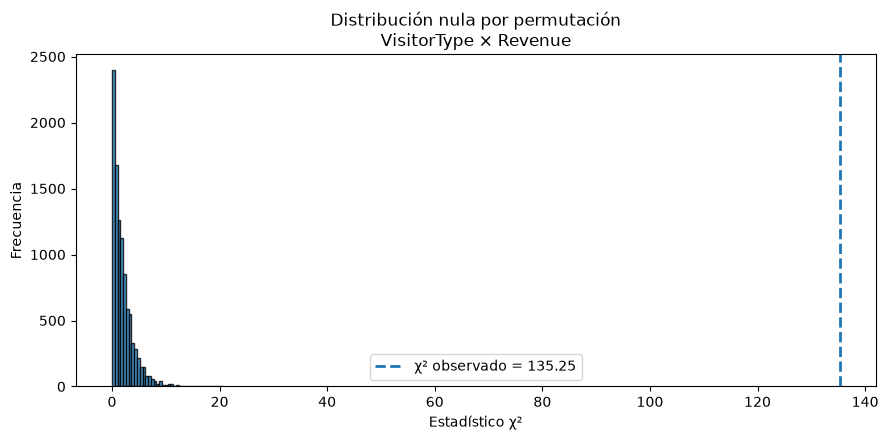

In [7]:
# 6.2 Validación adicional: VisitorType × Revenue mediante permutación de χ² 
tabla_obs = pd.crosstab(df["VisitorType"], df["Revenue"])

chi2_obs, p_chi2_asint, dof, expected = stats.chi2_contingency(
    tabla_obs, correction=False
)

print("Frecuencia esperada mínima:", expected.min())

rng_perm_chi2 = np.random.default_rng(RANDOM_STATE)

# Convertir a códigos enteros puros de NumPy fuera del bucle
visitor_codes = pd.Categorical(df["VisitorType"]).codes
revenue_codes = df["Revenue"].to_numpy(dtype=int)

# El tamaño de la tabla es 3 (VisitorType) x 2 (Revenue)
n_visitor = 3
n_revenue = 2

chi2_perm = np.empty(N_RESAMPLES)

for i in range(N_RESAMPLES):
    # Permutar la variable objetivo
    revenue_perm = rng_perm_chi2.permutation(revenue_codes)
    
    # Construcción de la tabla de contingencia usando np.bincount
    # Mapear las coordenadas 2D (visitor, revenue) a un índice 1D
    linear_indices = visitor_codes * n_revenue + revenue_perm
    tabla_perm = np.bincount(linear_indices, minlength=n_visitor * n_revenue).reshape(n_visitor, n_revenue)
    
    # Calcular chi2
    chi2_perm[i] = stats.chi2_contingency(tabla_perm, correction=False)[0]

p_perm_chi2 = (
    np.sum(chi2_perm >= chi2_obs) + 1
) / (N_RESAMPLES + 1)

print(f"χ² observado = {chi2_obs:.4f}")
print(f"Grados de libertad = {dof}")
print(f"p asintótico χ² = {p_chi2_asint:.4e}")
print(f"p permutación = {p_perm_chi2:.6f}")
print(f"Permutaciones = {N_RESAMPLES:,}")


fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(chi2_perm, bins=40, alpha=0.8, edgecolor="black")
ax.axvline(
    chi2_obs,
    linestyle="--",
    linewidth=2,
    label=f"χ² observado = {chi2_obs:.2f}"
)
ax.set_title("Distribución nula por permutación\nVisitorType × Revenue")
ax.set_xlabel("Estadístico χ²")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.show()


La prueba χ² asintótica (χ² = 135,2519; p ≈ 4,27 × 10⁻³⁰) y la prueba de permutación (p = 0,000100) conducen a la misma decisión inferencial: se rechaza H₀ de independencia entre VisitorType y Revenue. La concordancia entre ambos procedimientos indica que la conclusión obtenida en S1 no depende exclusivamente de la aproximación asintótica de χ². El p-valor de permutación no debe compararse numéricamente con el p-valor asintótico, ya que con 10.000 permutaciones su resolución mínima, utilizando la corrección +1, es aproximadamente 0,0001. A pesar de la fuerte evidencia estadística, el V de Cramér obtenido en S1 (≈ 0,105) indica una asociación de magnitud pequeña. Por tanto, existe evidencia robusta de asociación, pero no de una relación fuerte ni causal.

#### Interpretación

La prueba χ² asintótica de S1 y la prueba de permutación se interpretan comparando sus decisiones inferenciales. Si el p-valor empírico es inferior a α = 0,05, ambas metodologías respaldan el rechazo de la hipótesis de independencia entre `VisitorType` y `Revenue`.

Con 10.000 permutaciones y la corrección `+1`, el menor p-valor empírico posible es aproximadamente `1/10001 ≈ 0,0001`; por ello no debe interpretarse como equivalente numérico al p-valor asintótico extremadamente pequeño de S1.

La magnitud de la asociación debe interpretarse separadamente de la significancia estadística. En S1, **V de Cramér ≈ 0,105**, correspondiente a una asociación pequeña pese a la fuerte evidencia estadística contra la independencia.

Estos resultados describen asociación estadística y no establecen causalidad entre el tipo de visitante y la compra.


## 7. Estabilidad de correlaciones

Se evalúan cuatro correlaciones relevantes de S1 mediante **10.000 remuestras bootstrap de las filas**. Se reporta el IC percentil 95 %, su amplitud y si incluye cero.

Un intervalo concentrado alrededor del valor observado y que no incluya cero aporta evidencia de estabilidad muestral. Las correlaciones altas también se consideran como posible señal de redundancia entre variables para etapas posteriores.


In [8]:
# 7.1 Bootstrap de correlaciones
pares_corr = [
    ("BounceRates", "ExitRates"),
    ("ProductRelated", "ProductRelated_Duration"),
    ("Informational", "Informational_Duration"),
    ("Administrative", "Administrative_Duration")
]

def bootstrap_correlacion(a, b, n_resamples=N_RESAMPLES, seed=RANDOM_STATE):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    n = len(a)

    gen = np.random.default_rng(seed)
    vals = np.empty(n_resamples)

    batch = 250
    pos = 0

    while pos < n_resamples:
        m = min(batch, n_resamples - pos)
        idx = gen.integers(0, n, size=(m, n))

        aa = a[idx]
        bb = b[idx]

        aa_c = aa - aa.mean(axis=1, keepdims=True)
        bb_c = bb - bb.mean(axis=1, keepdims=True)

        num = np.sum(aa_c * bb_c, axis=1)
        den = np.sqrt(
            np.sum(aa_c**2, axis=1) *
            np.sum(bb_c**2, axis=1)
        )

        vals[pos:pos+m] = num / den
        pos += m

    return vals

corr_boot = {}
filas_corr = []

for i, (a, b) in enumerate(pares_corr):
    r_obs = df[[a, b]].corr().iloc[0, 1]
    boots = bootstrap_correlacion(
        df[a].to_numpy(),
        df[b].to_numpy(),
        seed=RANDOM_STATE + 100 + i
    )
    lo, hi = np.quantile(boots, [0.025, 0.975])

    corr_boot[(a, b)] = boots

    filas_corr.append({
        "variable_1": a,
        "variable_2": b,
        "r_observado": r_obs,
        "IC95_inf": lo,
        "IC95_sup": hi,
        "amplitud": hi - lo,
        "incluye_cero": lo <= 0 <= hi
    })

tabla_corr = pd.DataFrame(filas_corr)
display(tabla_corr)


,variable_1,variable_2,r_observado,IC95_inf,IC95_sup,amplitud,incluye_cero
0,BounceRates,ExitRates,0.913004,0.906614,0.919058,0.012443,False
1,ProductRelated,ProductRelated_Duration,0.860927,0.827588,0.886628,0.059039,False
2,Informational,Informational_Duration,0.618955,0.588544,0.652060,0.063516,False
3,Administrative,Administrative_Duration,0.601583,0.575472,0.628174,0.052701,False


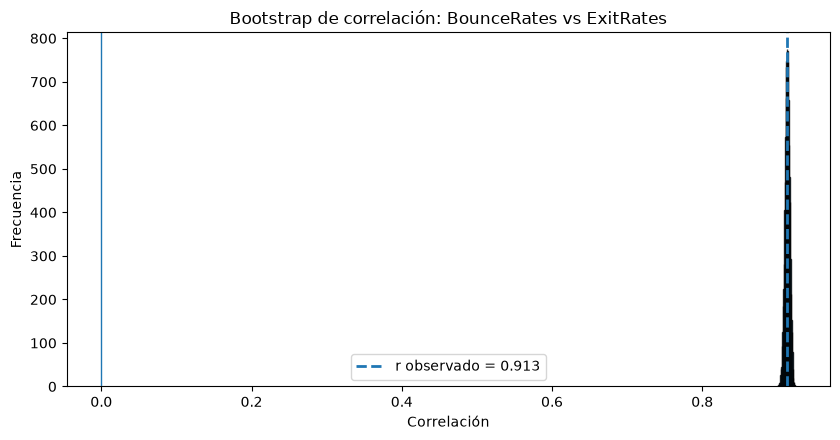

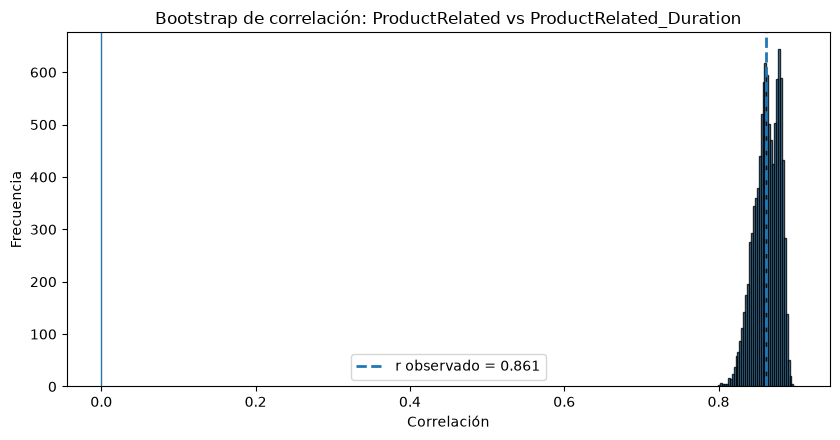

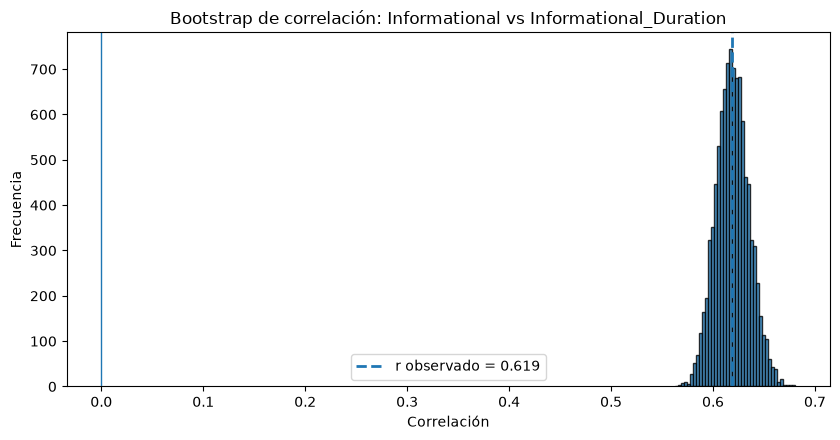

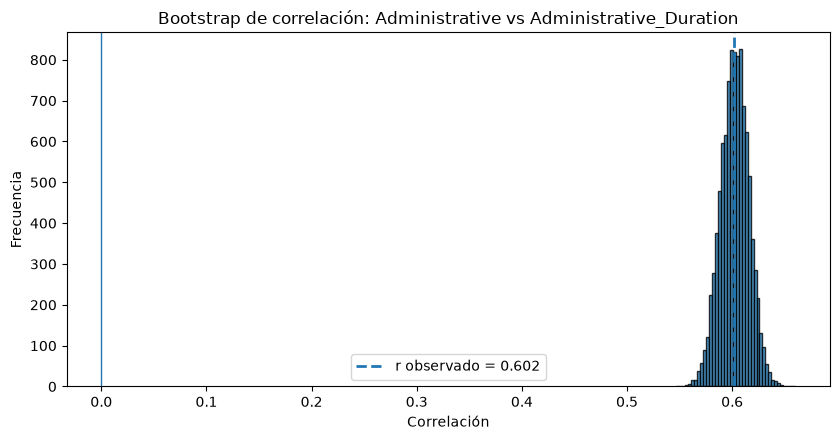

In [9]:
# 7.2 Visualización de distribuciones bootstrap de correlación
for (a, b), boots in corr_boot.items():
    r_obs = df[[a, b]].corr().iloc[0, 1]

    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    ax.hist(boots, bins=40, alpha=0.8, edgecolor="black")
    ax.axvline(r_obs, linestyle="--", linewidth=2,
               label=f"r observado = {r_obs:.3f}")
    ax.axvline(0, linewidth=1)
    ax.set_title(f"Bootstrap de correlación: {a} vs {b}")
    ax.set_xlabel("Correlación")
    ax.set_ylabel("Frecuencia")
    ax.legend()
    plt.tight_layout()
    plt.show()


### Interpretación

La estabilidad se evalúa considerando la amplitud de los intervalos y si éstos incluyen cero. Las correlaciones robustas pueden conservarse como relaciones descriptivas relevantes; sin embargo, correlaciones muy elevadas entre variables conceptualmente próximas pueden representar redundancia y deben considerarse con cautela en S3.


## 8. Simulación Monte Carlo

Se utiliza exclusivamente información estimada en S1. Sea `n = 12.330` y `p̂` la proporción observada de sesiones con compra. En cada una de **10.000 iteraciones** se simula el número de compras mediante una distribución binomial:

\[
X \sim Binomial(n,\hat{p})
\]

y se obtiene la tasa simulada `X/n`.

El objetivo no es realizar un pronóstico causal, sino estudiar el comportamiento de la tasa de conversión bajo un modelo probabilístico coherente con los parámetros observados en S1.


n = 12330
p de entrada = 0.154745
Media simulada = 0.154748
DE simulada = 0.003299
IC empírico 95% = [0.148337, 0.161152]


,iteraciones,media_acumulada,error_abs
0,100,0.154277,0.000467
1,500,0.154602,0.000143
2,1000,0.154771,0.000027
3,2500,0.154842,0.000098
4,5000,0.154805,0.000061
5,10000,0.154748,0.000003


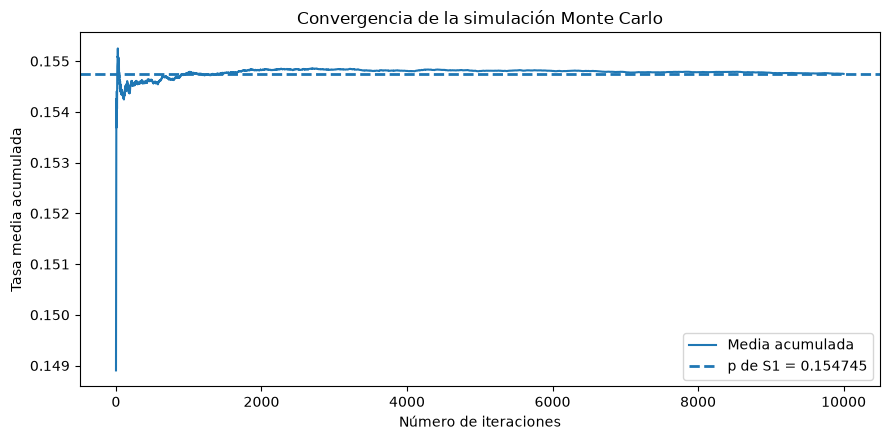

In [10]:
# 8.1 Monte Carlo y convergencia
n_ses = len(df)
p = df["Revenue"].mean()

rng_mc = np.random.default_rng(RANDOM_STATE)
compras_sim = rng_mc.binomial(n_ses, p, size=N_RESAMPLES)
tasas = compras_sim / n_ses

mc_media = tasas.mean()
mc_sd = tasas.std(ddof=1)
mc_ci = np.quantile(tasas, [0.025, 0.975])

print(f"n = {n_ses}")
print(f"p de entrada = {p:.6f}")
print(f"Media simulada = {mc_media:.6f}")
print(f"DE simulada = {mc_sd:.6f}")
print(f"IC empírico 95% = [{mc_ci[0]:.6f}, {mc_ci[1]:.6f}]")

puntos = [100, 500, 1000, 2500, 5000, 10000]
conv = []

for k in puntos:
    media_k = tasas[:k].mean()
    conv.append({
        "iteraciones": k,
        "media_acumulada": media_k,
        "error_abs": abs(media_k - p)
    })

tabla_conv = pd.DataFrame(conv)
display(tabla_conv)

media_acum = np.cumsum(tasas) / np.arange(1, N_RESAMPLES + 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.arange(1, N_RESAMPLES + 1), media_acum,
        label="Media acumulada")
ax.axhline(p, linestyle="--", linewidth=2,
           label=f"p de S1 = {p:.6f}")
ax.set_title("Convergencia de la simulación Monte Carlo")
ax.set_xlabel("Número de iteraciones")
ax.set_ylabel("Tasa media acumulada")
ax.legend()
plt.tight_layout()
plt.show()


### Interpretación de convergencia

La convergencia no requiere que el error disminuya de manera monótona en cada punto. Se espera fluctuación aleatoria, pero una estabilización progresiva de la media acumulada alrededor del parámetro de entrada a medida que aumenta el número de iteraciones.


## 9. Datos sintéticos y análisis de sensibilidad

Monte Carlo genera resultados sintéticos bajo un modelo probabilístico. Para evidenciar ID2.2 se crea además una muestra binaria sintética de `Revenue` con el mismo tamaño que S1.

Para ID2.3 se evalúan tres escenarios utilizando exclusivamente parámetros derivados de S1: límite inferior del IC 95 % de la proporción, estimación puntual y límite superior.


In [11]:
# 9.1 Datos sintéticos y sensibilidad
gen = np.random.default_rng(RANDOM_STATE)
rev_sint = gen.binomial(1, p, size=n_ses).astype(bool)

print("Tasa observada S1:", round(p, 6))
print("Tasa muestra sintética:", round(rev_sint.mean(), 6))

# IC normal aproximado de la proporción utilizado como referencia de S1
se_p = np.sqrt(p * (1 - p) / n_ses)
z = stats.norm.ppf(0.975)
p_inf = p - z * se_p
p_sup = p + z * se_p

escenarios = {
    "Límite inferior S1": p_inf,
    "Estimación puntual S1": p,
    "Límite superior S1": p_sup
}

filas_sens = []

for j, (nombre, p_esc) in enumerate(escenarios.items()):
    gen_esc = np.random.default_rng(RANDOM_STATE + 200 + j)
    tasas_esc = gen_esc.binomial(
        n_ses, p_esc, size=N_RESAMPLES
    ) / n_ses

    filas_sens.append({
        "escenario": nombre,
        "p_entrada": p_esc,
        "media_simulada": tasas_esc.mean(),
        "DE": tasas_esc.std(ddof=1),
        "P2.5": np.quantile(tasas_esc, 0.025),
        "P97.5": np.quantile(tasas_esc, 0.975)
    })

tabla_sens = pd.DataFrame(filas_sens)
display(tabla_sens)


Tasa observada S1: 0.154745
Tasa muestra sintética: 0.151906


,escenario,p_entrada,media_simulada,DE,P2.5,P97.5
0,Límite inferior S1,0.148361,0.148350,0.003225,0.142011,0.154663
1,Estimación puntual S1,0.154745,0.154672,0.003160,0.148500,0.160827
2,Límite superior S1,0.161128,0.161074,0.003315,0.154420,0.167640


### Interpretación de sensibilidad

La sensibilidad se interpreta observando cómo se desplaza la distribución simulada cuando cambia `p` dentro del rango de incertidumbre estimado en S1. Un desplazamiento coherente con los parámetros de entrada confirma que las conclusiones cuantitativas dependen del valor supuesto de la tasa de conversión, sin introducir escenarios externos o arbitrarios.


## 10. Robustez frente a outliers y observaciones influyentes

Se comparan **media, mediana y media recortada al 5 %**, y se aplica **jackknife** a la media.

Las cercas IQR se utilizan únicamente para diagnóstico; no se eliminan observaciones. El objetivo es evaluar cuánto cambian los resultados ante colas y observaciones extremas y distinguir sensibilidad distributiva de influencia individual.


In [12]:
# 10.1 Medidas robustas e IQR
filas_rob = []

for v in variables_ic:
    x = df[v].to_numpy(dtype=float)

    media = x.mean()
    mediana = np.median(x)
    media_rec = stats.trim_mean(x, proportiontocut=0.05)

    q1, q3 = np.quantile(x, [0.25, 0.75])
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr

    fuera = np.sum((x < li) | (x > ls))

    filas_rob.append({
        "variable": v,
        "media": media,
        "mediana": mediana,
        "media_recortada_5": media_rec,
        "cambio_rel_pct": 100 * (media_rec - media) / media,
        "n_fuera_IQR": fuera,
        "pct_fuera_IQR": 100 * fuera / len(x)
    })

tabla_rob = pd.DataFrame(filas_rob)
display(tabla_rob)


,variable,media,mediana,media_recortada_5,cambio_rel_pct,n_fuera_IQR,pct_fuera_IQR
0,ProductRelated_Duration,"1,194.746220",598.936905,925.059132,-22.572751,961,7.793998
1,PageValues,5.889258,0.000000,2.647401,-55.046957,2730,22.141119
2,ExitRates,0.043073,0.025156,0.036609,-15.005707,1099,8.913220


In [13]:
# 10.2 Jackknife exacto para la media
# Para la media, cada estimación leave-one-out puede calcularse sin bucles costosos.
filas_jack = []

for v in variables_ic:
    x = df[v].to_numpy(dtype=float)
    n = len(x)
    media = x.mean()

    jack = (x.sum() - x) / (n - 1)
    jack_mean = jack.mean()

    se_jack = np.sqrt(
        (n - 1) / n * np.sum((jack - jack_mean) ** 2)
    )

    cambios = np.abs(jack - media)
    idx = np.argmax(cambios)

    filas_jack.append({
        "variable": v,
        "media": media,
        "jack_mean": jack_mean,
        "SE_jackknife": se_jack,
        "max_cambio_leave_one_out": cambios[idx],
        "indice_mas_influyente": int(idx),
        "valor_mas_influyente": x[idx]
    })

tabla_jack = pd.DataFrame(filas_jack)
display(tabla_jack)


,variable,media,jack_mean,SE_jackknife,max_cambio_leave_one_out,indice_mas_influyente,valor_mas_influyente
0,ProductRelated_Duration,"1,194.746220","1,194.746220",17.233971,5.091960,8071,"63,973.522230"
1,PageValues,5.889258,5.889258,0.167222,0.028865,9239,361.763742
2,ExitRates,0.043073,0.043073,0.000438,0.000013,0,0.200000


### Criterio de robustez

La presencia de observaciones fuera de las cercas IQR no implica automáticamente que deban eliminarse. La robustez se evalúa mediante evidencia conjunta:

- estabilidad de los IC bootstrap;
- concordancia de las pruebas de permutación con S1;
- estabilidad de las correlaciones;
- convergencia Monte Carlo;
- diferencia entre media, mediana y media recortada;
- magnitud de la influencia jackknife.

Una distribución puede ser sensible globalmente a sus colas y, al mismo tiempo, no depender de una única observación.


## 11. Resultados validados para Sumativa 3

La siguiente celda genera `resultados_validados.csv` en `S2/resultados/`. Este archivo constituye un insumo trazable para la fase siguiente.


In [14]:
# 11.1 Exportación de resultados validados
salida = []

for _, r in tabla_boot.iterrows():
    salida.append([
        "Bootstrap",
        r["variable"],
        r["media"],
        r["IC_BCa_inf"],
        r["IC_BCa_sup"],
        "10.000 remuestras + IC percentil y BCa",
        "Estimación estable",
        "Conservar con cautela ante asimetría y extremos."
    ])

salida.append([
    "Permutación",
    "PageValues × Revenue",
    dif_obs,
    np.nan,
    np.nan,
    f"10.000 permutaciones; p={p_perm:.6g}",
    "Asociación robusta",
    "Mantener como asociación; revisar proximidad al target/leakage en S3."
])

salida.append([
    "Permutación χ²",
    "VisitorType × Revenue",
    chi2_obs,
    np.nan,
    np.nan,
    f"10.000 permutaciones; p={p_perm_chi2:.6g}",
    "Asociación robusta de magnitud pequeña",
    "Distinguir significancia estadística de V de Cramér ≈ 0,105."
])

for _, r in tabla_corr.iterrows():
    salida.append([
        "Correlación bootstrap",
        f'{r["variable_1"]} ~ {r["variable_2"]}',
        r["r_observado"],
        r["IC95_inf"],
        r["IC95_sup"],
        "IC bootstrap percentil 95%",
        "Correlación estable" if not r["incluye_cero"] else "Revisar estabilidad",
        "Evaluar redundancia entre variables correlacionadas en S3."
    ])

salida.append([
    "Monte Carlo",
    "Tasa de conversión",
    mc_media,
    mc_ci[0],
    mc_ci[1],
    "10.000 iteraciones + convergencia + sensibilidad",
    "Escenario estable",
    "Usar como referencia de incertidumbre, no como pronóstico causal."
])

# Incorporar las tres observaciones más influyentes ya calculadas en tabla_jack.
# Se conservan tanto el índice original (base cero) como el valor observado.
for _, r in tabla_jack.iterrows():
    salida.append([
        "Jackknife",
        r["variable"],
        r["max_cambio_leave_one_out"],
        np.nan,
        np.nan,
        (f'Índice original={int(r["indice_mas_influyente"])}; '
         f'valor observado={r["valor_mas_influyente"]:.8g}; '
         f'EE jackknife={r["SE_jackknife"]:.8g}'),
        "Observación individual más influyente",
        "Evaluar su influencia en S3; no eliminar sin evidencia de error."
    ])

resultados_validados = pd.DataFrame(
    salida,
    columns=[
        "metodo",
        "resultado",
        "estimacion",
        "limite_inf",
        "limite_sup",
        "validacion",
        "estado",
        "recomendacion_S3"
    ]
)

# Identificar de forma explícita qué representa la columna estimacion.
# Los intervalos conservan su significado según el método estadístico.
tipos_estimacion = {
    "Bootstrap": "Media muestral",
    "Permutación": "Diferencia de medias entre grupos",
    "Permutación χ²": "Estadístico chi-cuadrado",
    "Correlación bootstrap": "Coeficiente de correlación de Pearson",
    "Monte Carlo": "Proporción de compra simulada (media)",
    "Jackknife": "Cambio absoluto máximo de la media al excluir una observación"
}
resultados_validados.insert(
    2, "tipo_estimacion", resultados_validados["metodo"].map(tipos_estimacion)
)

salida_dir = Path("S2/resultados")
if not salida_dir.parent.exists():
    salida_dir = Path("resultados")

salida_dir.mkdir(parents=True, exist_ok=True)
archivo_salida = salida_dir / "resultados_validados.csv"

resultados_validados.to_csv(
    archivo_salida,
    index=False,
    encoding="utf-8-sig"
)

display(resultados_validados)
print("Archivo generado:", archivo_salida.resolve())


,metodo,resultado,tipo_estimacion,estimacion,limite_inf,limite_sup,validacion,estado,recomendacion_S3
0,Bootstrap,ProductRelated_Duration,Media muestral,"1,194.746220","1,162.484876","1,230.951845",10.000 remuestras + IC percentil y BCa,Estimación estable,Conservar con cautela ante asimetría y extremos.
1,Bootstrap,PageValues,Media muestral,5.889258,5.580391,6.234119,10.000 remuestras + IC percentil y BCa,Estimación estable,Conservar con cautela ante asimetría y extremos.
2,Bootstrap,ExitRates,Media muestral,0.043073,0.042238,0.043959,10.000 remuestras + IC percentil y BCa,Estimación estable,Conservar con cautela ante asimetría y extremos.
3,Permutación,PageValues × Revenue,Diferencia de medias entre grupos,25.288520,NaN,NaN,10.000 permutaciones; p=9.999e-05,Asociación robusta,Mantener como asociación; revisar proximidad a...
4,Permutación χ²,VisitorType × Revenue,Estadístico chi-cuadrado,135.251923,NaN,NaN,10.000 permutaciones; p=9.999e-05,Asociación robusta de magnitud pequeña,Distinguir significancia estadística de V de C...
5,Correlación bootstrap,BounceRates ~ ExitRates,Coeficiente de correlación de Pearson,0.913004,0.906614,0.919058,IC bootstrap percentil 95%,Correlación estable,Evaluar redundancia entre variables correlacio...
6,Correlación bootstrap,ProductRelated ~ ProductRelated_Duration,Coeficiente de correlación de Pearson,0.860927,0.827588,0.886628,IC bootstrap percentil 95%,Correlación estable,Evaluar redundancia entre variables correlacio...
7,Correlación bootstrap,Informational ~ Informational_Duration,Coeficiente de correlación de Pearson,0.618955,0.588544,0.652060,IC bootstrap percentil 95%,Correlación estable,Evaluar redundancia entre variables correlacio...
8,Correlación bootstrap,Administrative ~ Administrative_Duration,Coeficiente de correlación de Pearson,0.601583,0.575472,0.628174,IC bootstrap percentil 95%,Correlación estable,Evaluar redundancia entre variables correlacio...
9,Monte Carlo,Tasa de conversión,Proporción de compra simulada (media),0.154748,0.148337,0.161152,10.000 iteraciones + convergencia + sensibilidad,Escenario estable,"Usar como referencia de incertidumbre, no como..."


Archivo generado: D:\GDRive\Disco\Magister CDeIA\02 - ECTD (MCDI501)\repositorio\Estadistica_Computacional\S2\resultados\resultados_validados.csv


## 12. Síntesis crítica y conclusiones

### 12.1 Validación bootstrap

Los intervalos BCa de `ProductRelated_Duration`, `PageValues` y `ExitRates` deben compararse con los intervalos clásicos reportados en S1. La proximidad entre ambos procedimientos aporta evidencia de estabilidad inferencial frente al remuestreo, incluso en variables con asimetría marcada.

Esta estabilidad no implica que la media describa completamente la distribución. La diferencia entre media, mediana y media recortada se evalúa por separado en el análisis de robustez.

### 12.2 Validación de pruebas de hipótesis

Para `PageValues × Revenue`, la permutación basada en diferencia de medias se compara con la decisión obtenida mediante Mann–Whitney en S1. Debido a que los procedimientos utilizan estadísticos e hipótesis diferentes, sus p-valores no deben considerarse cantidades equivalentes; la comparación relevante es la concordancia de la decisión inferencial.

Adicionalmente, `VisitorType × Revenue` se valida manteniendo el mismo estadístico χ² de S1. Esta segunda prueba permite contrastar directamente el resultado asintótico con una distribución nula empírica obtenida mediante 10.000 permutaciones. Si ambas metodologías rechazan H₀, la evidencia de asociación no depende exclusivamente de la aproximación asintótica. Sin embargo, el V de Cramér de S1 (≈0,105) indica que la magnitud de la asociación es pequeña.

### 12.3 Estabilidad de correlaciones

Se evalúan cuatro correlaciones relevantes de S1 mediante bootstrap. La ausencia de cero en los IC 95 % respalda su estabilidad muestral. Las correlaciones más elevadas también deben considerarse como posibles señales de redundancia entre variables en las fases posteriores.

### 12.4 Monte Carlo, convergencia y sensibilidad

La simulación Monte Carlo utiliza exclusivamente `n` y la tasa de conversión estimada en S1. La media acumulada debe estabilizarse alrededor del parámetro de entrada a medida que aumenta el número de iteraciones, aunque el error no disminuya de forma estrictamente monótona.

El análisis de sensibilidad utiliza el límite inferior, la estimación puntual y el límite superior del IC de la proporción de S1. De esta forma se estudia la propagación de la incertidumbre sin introducir supuestos comerciales externos.

### 12.5 Robustez

La comparación entre media, mediana y media recortada permite detectar sensibilidad a colas y observaciones extremas. El jackknife complementa este análisis al medir cuánto cambia la media al retirar una observación a la vez.

Por ello, robustez no se interpreta como ausencia total de sensibilidad. Una estimación puede mostrar intervalos bootstrap estables y, simultáneamente, una diferencia importante entre la media y medidas robustas debido a la forma de la distribución.

### 12.6 Implicancias para S3

A partir de S2 se recomienda:

- conservar los parámetros cuyos intervalos se mantienen estables mediante bootstrap;
- considerar `PageValues` como una variable fuertemente asociada con `Revenue`, pero revisar su proximidad conceptual al resultado para evitar leakage en etapas predictivas;
- conservar la evidencia de asociación de `VisitorType`, distinguiendo significancia estadística de magnitud práctica;
- considerar la estabilidad y posible redundancia de las correlaciones elevadas;
- mantener las observaciones extremas salvo que exista evidencia de error, utilizando medidas robustas como complemento;
- utilizar `resultados_validados.csv` como insumo trazable para S3.

En conjunto, S2 fortalece las conclusiones de S1 mediante remuestreo y simulación, pero también muestra que estabilidad inferencial y robustez distributiva son conceptos distintos. Las conclusiones continúan siendo asociativas y no causales.


## 13. Limitaciones

- El análisis se basa en un único conjunto de datos observacional.
- Bootstrap y permutación evalúan estabilidad bajo supuestos de remuestreo e intercambiabilidad; no demuestran causalidad.
- El número de 10.000 remuestras/permutaciones limita la resolución mínima del p-valor empírico a aproximadamente `1/10001`.
- Monte Carlo reproduce un escenario probabilístico definido por parámetros de S1; no incorpora cambios estructurales externos.
- La presencia de asimetría y colas largas exige interpretar la media junto con medidas robustas.
- Correlaciones elevadas pueden reflejar variables parcialmente redundantes.


## 14. Referencias

- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall/CRC.
- Maidana, J. P. (2026). Material de la asignatura *Estadística Computacional para la Toma de Decisiones*. Universidad Andrés Bello.
- Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60.
- Sakar, C. O., & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q
- NumPy Developers. *NumPy documentation*.
- SciPy Developers. *SciPy documentation*.
